# 03 — Experiment 5: In-Edge-Work Partitioning

This notebook reports Experiment 5. It compares contiguous equal-vertex and in-edge-work partitioning while keeping the PageRank algorithm and full-vector communication unchanged.

In [1]:
from pathlib import Path
import os

ROOT = Path.cwd().resolve()
if not (ROOT / 'Makefile').exists():
    ROOT = ROOT.parent
assert (ROOT / 'Makefile').exists(), 'Start Jupyter from the project directory or its notebook subdirectory'
os.chdir(ROOT)
print('Project root located; working directory set successfully.')

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
for font_file in (ROOT / 'assets/fonts/latin-modern').glob('*.otf'):
    font_manager.fontManager.addfont(str(font_file))
plt.rcParams.update({'font.family': 'Latin Modern Roman', 'mathtext.fontset': 'cm'})

RAW = ROOT / 'results/vanda/e3/raw'
FIGURES = ROOT / 'results/vanda/e3/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
DATASET_ORDER = ['web-Google', 'web-BerkStan', 'enwiki-2013', 'uk-2002']
CONFIG_ORDER = ['32x1', '4x8']
PARTITION_ORDER = ['vertices', 'in-edges']
PARTITION_LABELS = {'vertices': 'Equal-vertex', 'in-edges': 'In-edge-work'}
COLORS = {'vertices': '#4C78A8', 'in-edges': '#E45756'}

Project root located; working directory set successfully.


## 1. Experimental Design

All runs use one Vanda node and 32 CPUs. The only algorithmic change is the MPI target partition.

| Version | Partition objective | Configurations | Warm-up | Measured runs |
|---|---|---|---:|---:|
| Equal-vertex | Similar number of target vertices | 32×1, 4×8 | 1 | 5 |
| In-edge-work | Similar sum of `1 + in-degree` | 32×1, 4×8 | 1 | 5 |

The in-edge-work policy retains the same full score vector, `MPI_Allreduce`, `MPI_Allgatherv`, OpenMP loops, stopping rule, and numerical parameters as the equal-vertex policy. Experiment 5 therefore isolates the effect of target partitioning.

## 2. Load and Validate Results

In [2]:
files = sorted(RAW.glob('*.csv'))
if not files:
    raise FileNotFoundError(
        'Experiment 5 CSV files are missing; run scripts/vanda/fetch_vanda_e3.sh after the jobs finish.'
    )

runs = pd.concat(
    (pd.read_csv(path).assign(source_file=path.name) for path in files),
    ignore_index=True,
)
parts = runs['run_id'].str.extract(
    r'^e3-(google|berkstan|enwiki|uk)-(vertices|in-edges)-(\d+)x(\d+)-rep(\d+)$'
)
parts.columns = ['dataset_key', 'partition_from_id', 'ranks_from_id',
                 'threads_from_id', 'repetition']
runs = pd.concat([runs, parts], axis=1)
for column in ['ranks_from_id', 'threads_from_id', 'repetition']:
    runs[column] = pd.to_numeric(runs[column])

name_map = {
    'google': 'web-Google',
    'berkstan': 'web-BerkStan',
    'enwiki': 'enwiki-2013',
    'uk': 'uk-2002',
}
runs['dataset_name'] = runs['dataset_key'].map(name_map)
runs['config'] = runs['mpi_ranks'].astype(str) + 'x' + runs['threads_per_rank'].astype(str)
runs['partition_label'] = runs['partition'].map(PARTITION_LABELS)

expected = pd.MultiIndex.from_product(
    [DATASET_ORDER, CONFIG_ORDER, PARTITION_ORDER],
    names=['dataset_name', 'config', 'partition'],
).to_frame(index=False)
counts = (runs.groupby(['dataset_name', 'config', 'partition'])
          .size().rename('measured_runs').reset_index())
completion = expected.merge(counts, how='left')
completion['measured_runs'] = completion['measured_runs'].fillna(0).astype(int)

checks = pd.Series({
    'rows': len(runs),
    'expected_rows': 80,
    'complete_configurations': completion['measured_runs'].eq(5).all(),
    'all_ids_parsed': parts.notna().all(axis=None),
    'all_converged': runs['converged'].eq(1).all(),
    'max_residual': runs['residual'].max(),
    'max_rank_sum_error': runs['rank_sum_error'].max(),
})
display(checks.to_frame('value'))
display(completion)
assert len(runs) == 80
assert checks['complete_configurations'] and checks['all_ids_parsed']
assert checks['all_converged'] and checks['max_rank_sum_error'] < 1e-9

,value
rows,80
expected_rows,80
complete_configurations,True
all_ids_parsed,True
all_converged,True
max_residual,0.0
max_rank_sum_error,0.0


,dataset_name,config,partition,measured_runs
0,web-Google,32x1,vertices,5
1,web-Google,32x1,in-edges,5
2,web-Google,4x8,vertices,5
3,web-Google,4x8,in-edges,5
4,web-BerkStan,32x1,vertices,5
5,web-BerkStan,32x1,in-edges,5
6,web-BerkStan,4x8,vertices,5
7,web-BerkStan,4x8,in-edges,5
8,enwiki-2013,32x1,vertices,5
9,enwiki-2013,32x1,in-edges,5


## 3. Median Summary

In [3]:
summary = (runs.groupby(['dataset_name', 'config', 'partition', 'mode',
                          'mpi_ranks', 'threads_per_rank'])
           .agg(runs=('solve_seconds', 'size'),
                median_s=('solve_seconds', 'median'),
                q1_s=('solve_seconds', lambda x: x.quantile(0.25)),
                q3_s=('solve_seconds', lambda x: x.quantile(0.75)),
                work_imbalance=('local_work_imbalance', 'median'),
                update_imbalance=('update_imbalance', 'median'),
                vertices_min=('local_vertices_min', 'median'),
                vertices_max=('local_vertices_max', 'median'),
                edges_min=('local_edges_min', 'median'),
                edges_max=('local_edges_max', 'median'),
                update_max_s=('update_max_seconds', 'median'),
                update_mean_s=('update_mean_seconds', 'median'),
                iterations=('iterations', 'median'))
           .reset_index())

equal_vertex = (summary[summary['partition'].eq('vertices')]
      .set_index(['dataset_name', 'config'])['median_s'])
summary['equal_vertex_median_s'] = [equal_vertex.loc[(d, c)] for d, c in zip(summary['dataset_name'], summary['config'])]
summary['in_edge_speedup_vs_equal'] = summary['equal_vertex_median_s'] / summary['median_s']

table = summary.copy()
for column in ['median_s', 'q1_s', 'q3_s', 'work_imbalance',
               'update_imbalance', 'in_edge_speedup_vs_equal']:
    table[column] = table[column].map(lambda x: f'{x:.3f}')
display(table[['dataset_name', 'config', 'partition', 'runs', 'median_s',
               'q1_s', 'q3_s', 'work_imbalance', 'update_imbalance',
               'in_edge_speedup_vs_equal']])

,dataset_name,config,partition,runs,median_s,q1_s,q3_s,work_imbalance,update_imbalance,in_edge_speedup_vs_equal
0,enwiki-2013,32x1,in-edges,5,3.203,3.202,3.203,1.065,1.087,1.297
1,enwiki-2013,32x1,vertices,5,4.155,4.155,4.156,2.099,1.809,1.000
2,enwiki-2013,4x8,in-edges,5,3.041,3.040,3.041,1.008,1.165,1.058
3,enwiki-2013,4x8,vertices,5,3.217,3.214,3.218,1.212,1.201,1.000
4,uk-2002,32x1,in-edges,5,12.798,12.798,12.802,1.000,1.102,1.044
5,uk-2002,32x1,vertices,5,13.362,13.340,13.377,1.355,1.340,1.000
6,uk-2002,4x8,in-edges,5,7.673,7.673,7.674,1.000,1.037,1.025
7,uk-2002,4x8,vertices,5,7.862,7.858,7.876,1.177,1.193,1.000
8,web-BerkStan,32x1,in-edges,5,0.493,0.492,0.494,1.072,1.349,1.159
9,web-BerkStan,32x1,vertices,5,0.571,0.571,0.572,2.924,2.657,1.000


## 4. Static Work and Measured Update Imbalance

`local_work_imbalance` is the maximum rank workload divided by the mean, where workload is vertices plus incoming edges. `update_imbalance` applies the same maximum/mean ratio to accumulated local update time.

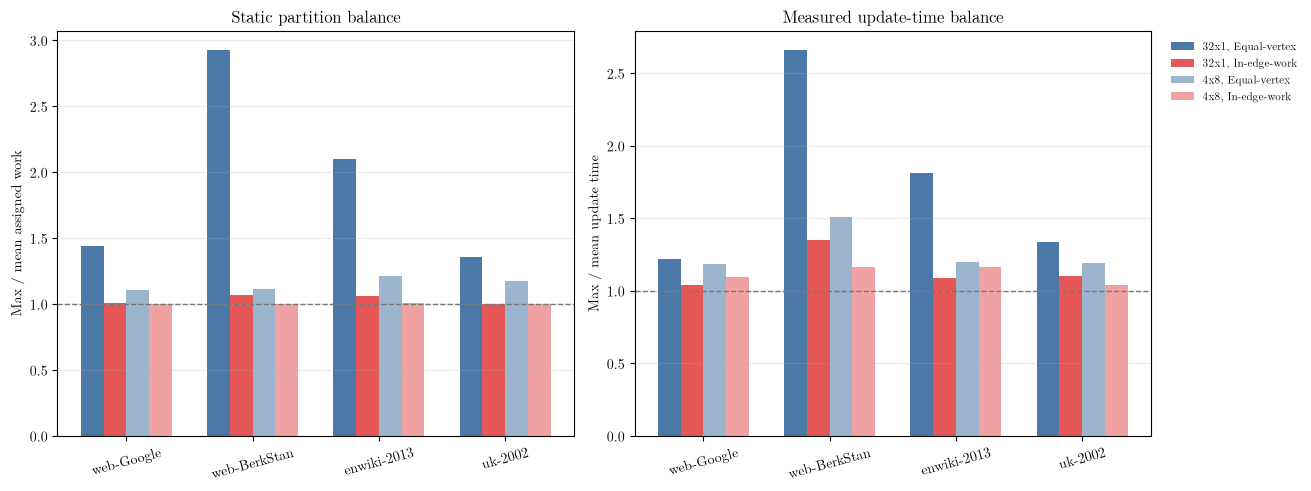

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
x = np.arange(len(DATASET_ORDER))
width = 0.18
positions = {
    ('32x1', 'vertices'): -1.5,
    ('32x1', 'in-edges'): -0.5,
    ('4x8', 'vertices'): 0.5,
    ('4x8', 'in-edges'): 1.5,
}
for config in CONFIG_ORDER:
    for partition in PARTITION_ORDER:
        part = (summary[(summary['config'].eq(config)) &
                        (summary['partition'].eq(partition))]
                .set_index('dataset_name').reindex(DATASET_ORDER))
        offset = positions[(config, partition)] * width
        label = f'{config}, {PARTITION_LABELS[partition]}'
        axes[0].bar(x + offset, part['work_imbalance'], width,
                    label=label, color=COLORS[partition],
                    alpha=1.0 if config == '32x1' else 0.55)
        axes[1].bar(x + offset, part['update_imbalance'], width,
                    label=label, color=COLORS[partition],
                    alpha=1.0 if config == '32x1' else 0.55)
for ax, title, ylabel in zip(
    axes,
    ['Static partition balance', 'Measured update-time balance'],
    ['Max / mean assigned work', 'Max / mean update time'],
):
    ax.axhline(1.0, color='#777777', linestyle='--', linewidth=1)
    ax.set_xticks(x, DATASET_ORDER, rotation=15)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.25)
axes[1].legend(frameon=False, fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(FIGURES / 'in_edge_partition_imbalance.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Runtime and In-Edge-Work Speedup

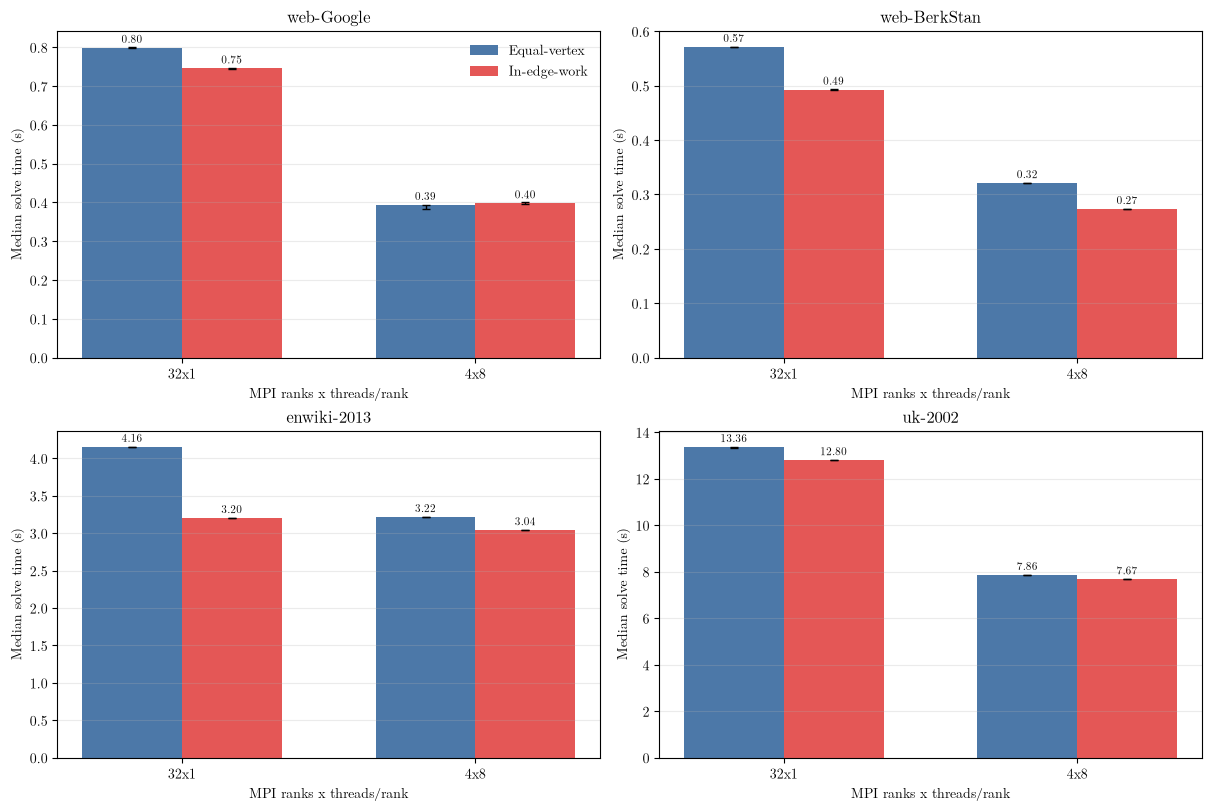

config,32x1,4x8
dataset_name,,
web-Google,1.071x,0.989x
web-BerkStan,1.159x,1.174x
enwiki-2013,1.297x,1.058x
uk-2002,1.044x,1.025x


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, dataset in zip(axes.flat, DATASET_ORDER):
    part = summary[summary['dataset_name'].eq(dataset)]
    x = np.arange(len(CONFIG_ORDER))
    for index, partition in enumerate(PARTITION_ORDER):
        values = (part[part['partition'].eq(partition)]
                  .set_index('config').reindex(CONFIG_ORDER))
        offset = (index - 0.5) * 0.34
        bars = ax.bar(x + offset, values['median_s'], 0.34,
                      color=COLORS[partition], label=PARTITION_LABELS[partition])
        ax.errorbar(x + offset, values['median_s'],
                    yerr=[values['median_s'] - values['q1_s'],
                          values['q3_s'] - values['median_s']],
                    fmt='none', color='black', capsize=3, linewidth=1)
        ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
    ax.set_xticks(x, CONFIG_ORDER)
    ax.set_title(dataset)
    ax.set_xlabel('MPI ranks x threads/rank')
    ax.set_ylabel('Median solve time (s)')
    ax.grid(axis='y', alpha=0.25)
axes[0, 0].legend(frameon=False)
fig.savefig(FIGURES / 'in_edge_partition_runtime.png', dpi=180, bbox_inches='tight')
plt.show()

speedup = (summary[summary['partition'].eq('in-edges')]
           .pivot(index='dataset_name', columns='config', values='in_edge_speedup_vs_equal')
           .reindex(DATASET_ORDER))
display(speedup.map(lambda value: f'{value:.3f}x'))

## 6. Results

- In-edge-work partitioning reduces static work imbalance and measured update-time imbalance in every dataset/configuration pair. The largest static correction is BerkStan `32×1`, where max/mean assigned work falls from 2.924 to 1.072.
- In-edge-work partitioning is faster in 7 of 8 comparisons. The largest gain is enwiki `32×1` at 1.297×, followed by BerkStan `4×8` at 1.174× and BerkStan `32×1` at 1.159×.
- Google `4×8` is the only regression: in-edge-work partitioning is about 1.1% slower despite better balance. This confirms that improved balance does not always offset partition-dependent cache and communication costs.
- All 80 measured runs converge and pass the residual and rank-sum checks. The policy changes ownership only; it does not change the PageRank solution.

## 7. Reproduce

On Vanda, enter the extracted project root (the directory containing `Makefile`) and submit the Experiment 5 suite:

```bash
test -f Makefile && test -d scripts/vanda
bash scripts/vanda/submit_vanda_e3.sh "$PWD"
```

From a local copy of the project, fetch completed results with your own Vanda login and the project path relative to your remote home directory, then run all cells:

```bash
bash scripts/vanda/fetch_vanda_e3.sh <nusnet-id>@vanda.nus.edu.sg DSA5208_Project3
```